In [ ]:
!pip -q install mne

import os
import urllib.request
import re
import mne

# 1. İndirilecek dosyaların listesi ve temel adres
base_url = "https://physionet.org/files/chbmit/1.0.0/"
files_to_download = [
    "chb01/chb01_03.edf", "chb01/chb01-summary.txt",
    "chb02/chb02_16.edf", "chb02/chb02-summary.txt",
    "chb03/chb03_01.edf", "chb03/chb03-summary.txt"
]

# 2. Dosyaları indirme döngüsü
for filepath in files_to_download:
    os.makedirs(os.path.dirname(filepath), exist_ok=True) # Klasörleri (chb01 vb.) oluştur
    if not os.path.exists(filepath):
        url = base_url + filepath
        print(f"İndiriliyor: {filepath} ...")
        urllib.request.urlretrieve(url, filepath)

# 3. İşlenecek kayıtların listesi
records = [
    {"edf": "chb01/chb01_03.edf", "summary": "chb01/chb01-summary.txt", "fname": "chb01_03.edf"},
    {"edf": "chb02/chb02_16.edf", "summary": "chb02/chb02-summary.txt", "fname": "chb02_16.edf"},
    {"edf": "chb03/chb03_01.edf", "summary": "chb03/chb03-summary.txt", "fname": "chb03_01.edf"}
]

# 4. Kayıtları sırayla okuma ve nöbet saatlerini çıkarma
for rec in records:
    print(f"\n{'-'*10} Kayıt: {rec['fname']} {'-'*10}")

    # EDF dosyasını MNE ile yükle
    raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)
    fs = raw.info['sfreq']
    n_chan = raw.info['nchan']
    ch_names = raw.info['ch_names']
    duration = raw.times[-1] # Son zaman damgası (saniye cinsinden)

    print(f"Örnekleme Frekansı (fs): {fs} Hz")
    print(f"Kanal Sayısı: {n_chan}")
    print(f"Süre: {duration:.2f} saniye")
    print(f"Kanallar: {ch_names}")

    # Summary dosyasını okuma
    with open(rec['summary'], 'r') as f:
        content = f.read()

    # Regex ile sadece bu dosyaya ait metin bloğunu (File Name: chb01_03.edf) yakalama.
    # (Sonraki 'File Name:' kelimesine ya da dosya sonuna kadar olan kısmı alır)
    pattern_block = rf"File Name:\s*{re.escape(rec['fname'])}\s*(.*?)(?=File Name:|$)"
    match_block = re.search(pattern_block, content, re.DOTALL)

    if match_block:
        block_text = match_block.group(1) # Sadece ilgili kaydın summary bilgisi

        # Nöbet başlangıç ve bitiş zamanlarını dinamik olarak yakalama
        start_pattern = r'Seizure(?:\s+\d+)?\s+Start Time:\s*(\d+)'
        end_pattern = r'Seizure(?:\s+\d+)?\s+End Time:\s*(\d+)'

        starts = re.findall(start_pattern, block_text)
        ends = re.findall(end_pattern, block_text)

        if starts and ends:
            for s, e in zip(starts, ends):
                print(f"--> NÖBET TESPİT EDİLDİ: Başlangıç: {s} sn, Bitiş: {e} sn")
        else:
            print("--> Bu kayıtta nöbet tespit edilmedi.")
    else:
        print("--> Summary dosyasında bu kayda ait blok bulunamadı.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 32.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
İndiriliyor: chb01/chb01_03.edf ...
İndiriliyor: chb01/chb01-summary.txt ...
İndiriliyor: chb02/chb02_16.edf ...
İndiriliyor: chb02/chb02-summary.txt ...
İndiriliyor: chb03/chb03_01.edf ...
İndiriliyor: chb03/chb03-summary.txt ...

---------- Kayıt: chb01_03.edf ----------


/tmp/ipykernel_1880/4180800638.py:36: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)


Örnekleme Frekansı (fs): 256.0 Hz
Kanal Sayısı: 23
Süre: 3600.00 saniye
Kanallar: ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1']
--> NÖBET TESPİT EDİLDİ: Başlangıç: 2996 sn, Bitiş: 3036 sn

---------- Kayıt: chb02_16.edf ----------
Örnekleme Frekansı (fs): 256.0 Hz
Kanal Sayısı: 23
Süre: 959.00 saniye
Kanallar: ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1']
--> NÖBET TESPİT EDİLDİ: Başlangıç: 130 sn, Bitiş: 212 sn

---------- Kayıt: chb03_01.edf ----------
Örnekleme Frekansı (fs): 256.0 Hz
Kanal Sayısı: 23
Süre: 3600.00 saniye
Kanallar: ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-

/tmp/ipykernel_1880/4180800638.py:36: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)
/tmp/ipykernel_1880/4180800638.py:36: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)


In [ ]:
import numpy as np
import pandas as pd

window_sec = 2 # 2 saniyelik pencereler
pencere_verileri = []

# T8-P8-1 mükerrer olduğu için sadece 'T8-P8-0'ı (veya orijinal kanalları) almak daha iyidir.
# Biz toplam çizgi uzunluğunu tüm kanalların ortalaması (veya toplamı) olarak alabiliriz.
# Bu kodda her pencerenin tüm kanallarındaki çizgi uzunluklarının ortalamasını alacağız.

for rec in records:
    print(f"{rec['fname']} işleniyor...")
    raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)
    data, times = raw[:] # Tüm veri (Kanal Sayısı x Örnek Sayısı)
    fs = int(raw.info['sfreq'])

    # Summary'den nöbet saniyelerini bul
    with open(rec['summary'], 'r') as f:
        content = f.read()
    pattern_block = rf"File Name:\s*{re.escape(rec['fname'])}\s*(.*?)(?=File Name:|$)"
    match_block = re.search(pattern_block, content, re.DOTALL)

    starts, ends = [], []
    if match_block:
        block_text = match_block.group(1)
        start_pattern = r'Seizure(?:\s+\d+)?\s+Start Time:\s*(\d+)'
        end_pattern = r'Seizure(?:\s+\d+)?\s+End Time:\s*(\d+)'
        starts = [int(s) for s in re.findall(start_pattern, block_text)]
        ends = [int(e) for e in re.findall(end_pattern, block_text)]

    # 2 saniyelik pencereler halinde döngü
    samples_per_window = window_sec * fs
    n_windows = data.shape[1] // samples_per_window

    for i in range(n_windows):
        start_idx = i * samples_per_window
        end_idx = start_idx + samples_per_window
        window_data = data[:, start_idx:end_idx]

        # Çizgi uzunluğu (Line Length) hesabı: Ardışık farkların mutlak toplamı
        # NumPy diff ile ardışık farkları alıp mutlak değerlerini topluyoruz
        line_length_per_channel = np.sum(np.abs(np.diff(window_data, axis=1)), axis=1)
        mean_line_length = np.mean(line_length_per_channel) # Tüm kanalların ortalaması

        # Bu pencere nöbete denk geliyor mu?
        # Pencerenin saniye cinsinden zaman aralığı
        win_start_sec = i * window_sec
        win_end_sec = win_start_sec + window_sec

        is_seizure = 0
        for s, e in zip(starts, ends):
            # Eğer pencere nöbet süresiyle kesişiyorsa 1 yap
            if not (win_end_sec <= s or win_start_sec >= e):
                is_seizure = 1
                break

        pencere_verileri.append({
            'Hasta_Kayit': rec['fname'],
            'Pencere_No': i,
            'Baslangic_Sn': win_start_sec,
            'Line_Length': mean_line_length,
            'Nobet_Durumu': is_seizure
        })

# Pandas veri çerçevesine dönüştür
df = pd.DataFrame(pencere_verileri)
print("\nÖzellik çıkarımı tamamlandı!")
print(f"Toplam Pencere Sayısı: {len(df)}")
print("\nVeri Setinden İlk 5 Satır:")
display(df.head())
print("\nNöbet Olan/Olmayan Pencere Sayıları:")
print(df['Nobet_Durumu'].value_counts())

chb01_03.edf işleniyor...


/tmp/ipykernel_1880/13279943.py:13: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)


chb02_16.edf işleniyor...
chb03_01.edf işleniyor...


/tmp/ipykernel_1880/13279943.py:13: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)
/tmp/ipykernel_1880/13279943.py:13: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(rec['edf'], preload=True, verbose=False)



Özellik çıkarımı tamamlandı!
Toplam Pencere Sayısı: 4079

Veri Setinden İlk 5 Satır:


,Hasta_Kayit,Pencere_No,Baslangic_Sn,Line_Length,Nobet_Durumu
0,chb01_03.edf,0,0,0.002649,0
1,chb01_03.edf,1,2,0.003088,0
2,chb01_03.edf,2,4,0.002358,0
3,chb01_03.edf,3,6,0.002100,0
4,chb01_03.edf,4,8,0.002776,0



Nöbet Olan/Olmayan Pencere Sayıları:
Nobet_Durumu
0    3992
1      87
Name: count, dtype: int64


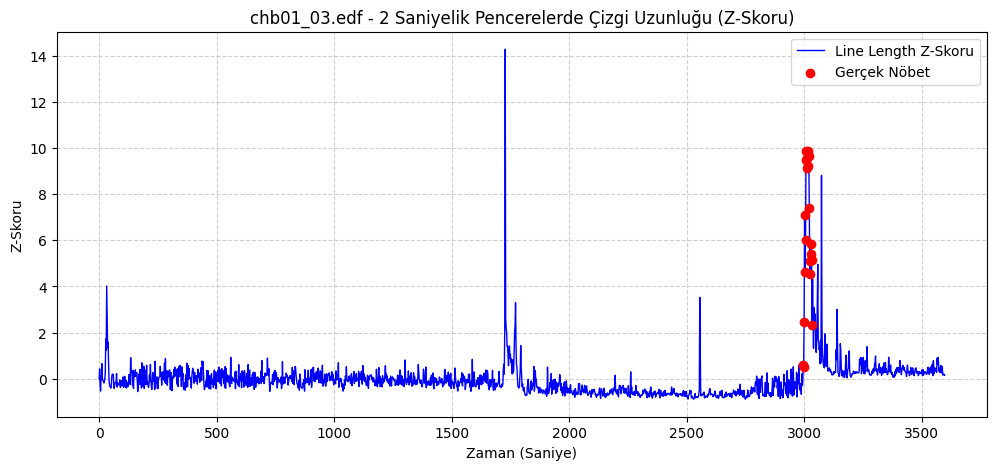

Z-skoru eklenmiş veri setinden ilk 5 satır:


,Hasta_Kayit,Pencere_No,Baslangic_Sn,Line_Length,Nobet_Durumu,Z_Score
0,chb01_03.edf,0,0,0.002649,0,-0.001886
1,chb01_03.edf,1,2,0.003088,0,0.425122
2,chb01_03.edf,2,4,0.002358,0,-0.285267
3,chb01_03.edf,3,6,0.002100,0,-0.536402
4,chb01_03.edf,4,8,0.002776,0,0.121010


In [ ]:
import matplotlib.pyplot as plt

# 1. Z-Skoru Hesaplama (Her kayıt için kendi içinde)
# Z = (Değer - Ortalama) / Standart Sapma
df['Z_Score'] = df.groupby('Hasta_Kayit')['Line_Length'].transform(lambda x: (x - x.mean()) / x.std())

# 2. Şekil çizimi için ilk kaydı (chb01_03.edf) filtreleme
ornek_hasta = 'chb01_03.edf'
df_ornek = df[df['Hasta_Kayit'] == ornek_hasta]

# 3. Grafik (Şekil) figürünü oluşturma
plt.figure(figsize=(12, 5))

# 4. Z-skoru değerlerini zamana (saniye) göre mavi çizgi olarak çizdirme
plt.plot(df_ornek['Baslangic_Sn'], df_ornek['Z_Score'], label='Line Length Z-Skoru', color='blue', linewidth=1)

# 5. Nöbet anlarını (Nobet_Durumu == 1) bulup kırmızı noktalarla grafiğe ekleme
nobetler = df_ornek[df_ornek['Nobet_Durumu'] == 1]
plt.scatter(nobetler['Baslangic_Sn'], nobetler['Z_Score'], color='red', label='Gerçek Nöbet', zorder=5)

# 6. Grafiğin başlık, eksen isimleri ve ızgarasını ayarlama
plt.title(f"{ornek_hasta} - 2 Saniyelik Pencerelerde Çizgi Uzunluğu (Z-Skoru)")
plt.xlabel("Zaman (Saniye)")
plt.ylabel("Z-Skoru")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# 7. Grafiği ekranda gösterme
plt.show()

# 8. Z-skoru sütununun başarıyla eklendiğini görmek için ilk 5 satırı yazdırma
print("Z-skoru eklenmiş veri setinden ilk 5 satır:")
display(df.head())

In [ ]:
from sklearn.metrics import f1_score

# 1. Hasta ID'lerini dosya adından çıkarma (chb01, chb02, chb03)
df['Hasta_ID'] = df['Hasta_Kayit'].apply(lambda x: x.split('_')[0])
hastalar = df['Hasta_ID'].unique()

# 2. Denenecek Z-skoru eşikleri (0'dan 20'ye kadar 0.1 adımlarla)
thresholds = np.arange(0, 20, 0.1)

print("--- Nöbet Tespiti F1 Skoru (Z-Skoru Eşikleme) ---")
genel_f1_listesi = []
iyimser_f1_listesi = []

# 3. Her hastayı sırayla test setine ayırma (Leave-One-Patient-Out)
for test_hasta in hastalar:
    # 4. Eğitim (diğer hastalar) ve Test (test hastası) verilerini ayır
    train_df = df[df['Hasta_ID'] != test_hasta]
    test_df = df[df['Hasta_ID'] == test_hasta]

    y_train_true = train_df['Nobet_Durumu']
    y_test_true = test_df['Nobet_Durumu']

    # 5. Eğitim verisinde F1'i en yüksek yapan 'genel eşiği' bulma
    best_train_f1, best_train_th = 0, 0
    for th in thresholds:
        y_pred = (train_df['Z_Score'] > th).astype(int)
        f1 = f1_score(y_train_true, y_pred, zero_division=0)
        if f1 > best_train_f1:
            best_train_f1, best_train_th = f1, th

    # 6. Test verisinin kendisinde F1'i en yüksek yapan 'iyimser eşiği' bulma
    best_test_f1, best_test_th = 0, 0
    for th in thresholds:
        y_pred = (test_df['Z_Score'] > th).astype(int)
        f1 = f1_score(y_test_true, y_pred, zero_division=0)
        if f1 > best_test_f1:
            best_test_f1, best_test_th = f1, th

    # 7. Diğer hastalardan bulduğumuz genel eşiği, görmediğimiz test hastasına uygulama
    y_test_pred_genel = (test_df['Z_Score'] > best_train_th).astype(int)
    f1_genel = f1_score(y_test_true, y_test_pred_genel, zero_division=0)

    genel_f1_listesi.append(f1_genel)
    iyimser_f1_listesi.append(best_test_f1)

    print(f"\nTest Hastası: {test_hasta}")
    print(f"  - Diğer hastalardan öğrenilen eşik: {best_train_th:.2f} -> Bu eşikle Genel F1: {f1_genel:.3f}")
    print(f"  - Hastanın kendine özel en iyi eşiği: {best_test_th:.2f} -> İyimser F1: {best_test_f1:.3f}")

# 8. Tüm hastalar için ortalama skorları yazdırma
print("\n=== SONUÇ (ORTALAMA) ===")
print(f"Ortalama Genel F1 (Gerçekçi Baseline): {np.mean(genel_f1_listesi):.3f}")
print(f"Ortalama İyimser F1 (Hastaya Özel Üst Sınır): {np.mean(iyimser_f1_listesi):.3f}")

--- Nöbet Tespiti F1 Skoru (Z-Skoru Eşikleme) ---

Test Hastası: chb01
  - Diğer hastalardan öğrenilen eşik: 1.80 -> Bu eşikle Genel F1: 0.590
  - Hastanın kendine özel en iyi eşiği: 4.40 -> İyimser F1: 0.821

Test Hastası: chb02
  - Diğer hastalardan öğrenilen eşik: 3.80 -> Bu eşikle Genel F1: 0.000
  - Hastanın kendine özel en iyi eşiği: 0.10 -> İyimser F1: 0.312

Test Hastası: chb03
  - Diğer hastalardan öğrenilen eşik: 4.40 -> Bu eşikle Genel F1: 0.233
  - Hastanın kendine özel en iyi eşiği: 2.00 -> İyimser F1: 0.424

=== SONUÇ (ORTALAMA) ===
Ortalama Genel F1 (Gerçekçi Baseline): 0.274
Ortalama İyimser F1 (Hastaya Özel Üst Sınır): 0.519


In [1]:
!pip -q install mne

import os, re, urllib.request, warnings
import mne

warnings.filterwarnings("ignore", category=RuntimeWarning)

AWS = "https://physionet-open.s3.amazonaws.com/chbmit/1.0.0/"
YEDEK = "https://physionet.org/files/chbmit/1.0.0/"

dosyalar = [
    "chb05/chb05_06.edf", "chb05/chb05-summary.txt",
    "chb08/chb08_02.edf", "chb08/chb08-summary.txt",
]

for yol in dosyalar:
    os.makedirs(os.path.dirname(yol), exist_ok=True)
    if os.path.exists(yol) and os.path.getsize(yol) > 0:
        print(f"Zaten var: {yol}")
        continue
    for taban in (AWS, YEDEK):
        try:
            urllib.request.urlretrieve(taban + yol, yol)
            print(f"İndirildi ({taban.split('/')[2]}): {yol} -> {os.path.getsize(yol)/1e6:.2f} MB")
            break
        except Exception as hata:
            print(f"UYARI: {taban.split('/')[2]} üzerinden inmedi: {yol} ({hata})")
            if os.path.exists(yol):
                os.remove(yol)
    else:
        raise RuntimeError(f"Hiçbir adresten inmedi: {yol}")

yeni_kayitlar = [
    {"edf": "chb05/chb05_06.edf", "summary": "chb05/chb05-summary.txt", "fname": "chb05_06.edf"},
    {"edf": "chb08/chb08_02.edf", "summary": "chb08/chb08-summary.txt", "fname": "chb08_02.edf"},
]

baslangic_deseni = r'Seizure(?:\s+\d+)?\s+Start Time:\s*(\d+)'
bitis_deseni = r'Seizure(?:\s+\d+)?\s+End Time:\s*(\d+)'

for kayit in yeni_kayitlar:
    print(f"\n---------- Kayıt: {kayit['fname']} ----------")

    raw = mne.io.read_raw_edf(kayit["edf"], preload=True, verbose=False)
    kanallar = raw.info["ch_names"]
    kopya = [k for k in kanallar if re.search(r'-\d+$', k) and k.rsplit('-', 1)[0] + '-0' in kanallar]
    print(f"Örnekleme frekansı (fs): {raw.info['sfreq']} Hz")
    print(f"Kanal sayısı: {raw.info['nchan']}")
    print(f"Süre: {raw.times[-1]:.2f} sn")
    print(f"Kanallar: {kanallar}")
    print(f"MNE'nin numaraladığı mükerrer kanallar: {kopya}")

    with open(kayit["summary"], "r") as f:
        icerik = f.read()

    # Dosya adı .edf dahil tam eşleşir; satır sonu şartı 'chb05_06+.edf' gibi adları dışarıda bırakır
    blok_deseni = rf"File Name:\s*{re.escape(kayit['fname'])}\s*\n(.*?)(?=File Name:|\Z)"
    blok = re.search(blok_deseni, icerik, re.DOTALL)

    if not blok:
        print("--> Summary dosyasında bu kayda ait blok bulunamadı.")
        continue

    metin = blok.group(1)
    nobet_sayisi = re.search(r'Number of Seizures in File:\s*(\d+)', metin)
    baslar = [int(x) for x in re.findall(baslangic_deseni, metin)]
    bitisler = [int(x) for x in re.findall(bitis_deseni, metin)]

    print(f"Summary'deki nöbet sayısı: {nobet_sayisi.group(1) if nobet_sayisi else 'bulunamadı'}")
    if baslar and len(baslar) == len(bitisler):
        for s, e in zip(baslar, bitisler):
            print(f"--> NÖBET: Başlangıç {s} sn, Bitiş {e} sn (süre {e - s} sn)")
    else:
        print(f"--> Nöbet eşleşmesi tutarsız: başlangıç={baslar}, bitiş={bitisler}")

print("\n--- Önceki 3 kayıt Colab'da duruyor mu? ---")
for yol in ["chb01/chb01_03.edf", "chb02/chb02_16.edf", "chb03/chb03_01.edf",
            "chb01/chb01-summary.txt", "chb02/chb02-summary.txt", "chb03/chb03-summary.txt"]:
    print(f"{yol}: {'var' if os.path.exists(yol) else 'YOK'}")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
İndirildi (physionet-open.s3.amazonaws.com): chb05/chb05_06.edf -> 42.40 MB
İndirildi (physionet-open.s3.amazonaws.com): chb05/chb05-summary.txt -> 0.00 MB
İndirildi (physionet-open.s3.amazonaws.com): chb08/chb08_02.edf -> 42.40 MB
İndirildi (physionet-open.s3.amazonaws.com): chb08/chb08-summary.txt -> 0.00 MB

---------- Kayıt: chb05_06.edf ----------
Örnekleme frekansı (fs): 256.0 Hz
Kanal sayısı: 23
Süre: 3600.00 sn
Kanallar: ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1']
MNE'nin numa

In [2]:
!pip -q install mne

import os, re, urllib.request, warnings
import numpy as np
import pandas as pd
import mne

warnings.filterwarnings("ignore", category=RuntimeWarning)

AWS = "https://physionet-open.s3.amazonaws.com/chbmit/1.0.0/"
YEDEK = "https://physionet.org/files/chbmit/1.0.0/"

hastalar = {
    "chb01": "chb01_03.edf",
    "chb02": "chb02_16.edf",
    "chb03": "chb03_01.edf",
    "chb05": "chb05_06.edf",
    "chb08": "chb08_02.edf",
}

# 1) İndirme (yalnız bu 5 kayıt + 5 summary; varsa atlar)
def indir(yol):
    os.makedirs(os.path.dirname(yol), exist_ok=True)
    if os.path.exists(yol) and os.path.getsize(yol) > 0:
        return
    for taban in (AWS, YEDEK):
        try:
            urllib.request.urlretrieve(taban + yol, yol)
            print(f"İndirildi ({taban.split('/')[2]}): {yol}")
            return
        except Exception as hata:
            print(f"UYARI: {taban.split('/')[2]} üzerinden inmedi: {yol} ({hata})")
            if os.path.exists(yol):
                os.remove(yol)
    raise RuntimeError(f"Hiçbir adresten inmedi: {yol}")

for hasta, fname in hastalar.items():
    indir(f"{hasta}/{fname}")
    indir(f"{hasta}/{hasta}-summary.txt")

# 2) Özellik çıkarımı: 2 sn pencere, çizgi uzunluğu (23 kanalın ortalaması), nöbet etiketi
PENCERE_SN = 2
baslangic_deseni = r'Seizure(?:\s+\d+)?\s+Start Time:\s*(\d+)'
bitis_deseni = r'Seizure(?:\s+\d+)?\s+End Time:\s*(\d+)'

satirlar = []
for hasta, fname in hastalar.items():
    raw = mne.io.read_raw_edf(f"{hasta}/{fname}", preload=True, verbose=False)
    fs = int(raw.info["sfreq"])
    veri = raw.get_data()
    ornek = PENCERE_SN * fs
    n_pencere = veri.shape[1] // ornek
    kesit = veri[:, :n_pencere * ornek].reshape(veri.shape[0], n_pencere, ornek)
    cizgi_uzunlugu = np.abs(np.diff(kesit, axis=2)).sum(axis=2).mean(axis=0)
    del veri, kesit, raw

    with open(f"{hasta}/{hasta}-summary.txt", "r") as f:
        icerik = f.read()
    blok = re.search(rf"File Name:\s*{re.escape(fname)}\s*\n(.*?)(?=File Name:|\Z)", icerik, re.DOTALL)
    if not blok:
        raise RuntimeError(f"Summary'de blok yok: {fname}")
    baslar = [int(x) for x in re.findall(baslangic_deseni, blok.group(1))]
    bitisler = [int(x) for x in re.findall(bitis_deseni, blok.group(1))]
    if not baslar or len(baslar) != len(bitisler):
        raise RuntimeError(f"Nöbet eşleşmesi tutarsız: {fname} {baslar} {bitisler}")

    bas = np.arange(n_pencere) * PENCERE_SN
    bit = bas + PENCERE_SN
    etiket = np.zeros(n_pencere, dtype=int)
    for s, e in zip(baslar, bitisler):
        etiket[(bit > s) & (bas < e)] = 1

    z = (cizgi_uzunlugu - cizgi_uzunlugu.mean()) / cizgi_uzunlugu.std(ddof=1)
    satirlar.append(pd.DataFrame({
        "Hasta_ID": hasta, "Hasta_Kayit": fname, "Pencere_No": np.arange(n_pencere),
        "Baslangic_Sn": bas, "Line_Length": cizgi_uzunlugu, "Z_Score": z, "Nobet_Durumu": etiket,
    }))
    print(f"{fname}: {n_pencere} pencere, nöbet aralığı(ları) {list(zip(baslar, bitisler))}, etiketli pencere {etiket.sum()}")

df = pd.concat(satirlar, ignore_index=True)
df.to_csv("ozellikler.csv", index=False)

ilk3 = df[df["Hasta_ID"].isin(["chb01", "chb02", "chb03"])]
print(f"\nKONTROL (Aşama 2 ile aynı olmalı: 4079 pencere, 87 nöbetli): "
      f"{len(ilk3)} pencere, {ilk3['Nobet_Durumu'].sum()} nöbetli")
print(f"Toplam: {len(df)} pencere, {df['Nobet_Durumu'].sum()} nöbetli\n")

# 3) Ölçüt fonksiyonları (pencere düzeyinde: doğru alarm = TP, yanlış alarm = FP, kaçırılan = FN)
def sayac(y, tahmin):
    tp = int(((tahmin == 1) & (y == 1)).sum())
    fp = int(((tahmin == 1) & (y == 0)).sum())
    fn = int(((tahmin == 0) & (y == 1)).sum())
    return tp, fp, fn

def f1(tp, fp, fn):
    payda = 2 * tp + fp + fn
    return 2 * tp / payda if payda > 0 else 0.0

esikler = np.round(np.arange(0, 20, 0.1), 1)

def en_iyi_esik(y, z):
    skorlar = [f1(*sayac(y, (z > t).astype(int))) for t in esikler]
    i = int(np.argmax(skorlar))
    return float(esikler[i]) if skorlar[i] > 0 else 0.0

# 4) Her hasta için üç yöntem
sonuc = []
for test_hasta in hastalar:
    test = df[df["Hasta_ID"] == test_hasta]
    egitim = df[df["Hasta_ID"] != test_hasta]
    yt, zt = test["Nobet_Durumu"].to_numpy(), test["Z_Score"].to_numpy()

    # a) Sabit z>3 baseline (eşik hiçbir veriden ayarlanmaz)
    a = sayac(yt, (zt > 3).astype(int))
    # b) Bir-hasta-dışarıda: eşik yalnız diğer 4 hastadan seçilir, teste uygulanır
    esik_lopo = en_iyi_esik(egitim["Nobet_Durumu"].to_numpy(), egitim["Z_Score"].to_numpy())
    b = sayac(yt, (zt > esik_lopo).astype(int))
    # c) İyimser üst sınır: eşik test hastasının kendisinden seçilir (gerçek sonuç DEĞİL)
    esik_iyi = en_iyi_esik(yt, zt)
    c = sayac(yt, (zt > esik_iyi).astype(int))

    sonuc.append({
        "Hasta": test_hasta, "Nobetli_Pencere": int(yt.sum()),
        "z3_TP": a[0], "z3_FP": a[1], "z3_FN": a[2], "z3_F1": f1(*a),
        "LOPO_esik": esik_lopo, "LOPO_TP": b[0], "LOPO_FP": b[1], "LOPO_FN": b[2], "LOPO_F1": f1(*b),
        "Iyimser_esik": esik_iyi, "Iyimser_TP": c[0], "Iyimser_FP": c[1], "Iyimser_FN": c[2], "Iyimser_F1": f1(*c),
    })

tablo = pd.DataFrame(sonuc)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print("=== HASTA BAŞINA SONUÇLAR (pencere düzeyi) ===")
print(tablo.round(3).to_string(index=False))

print("\n=== ORTALAMA ± STANDART SAPMA (N-1, 5 hasta) ===")
for ad, on in [("z>3 baseline", "z3"), ("Bir-hasta-dışarıda eşik", "LOPO"), ("İyimser üst sınır", "Iyimser")]:
    parcalar = []
    for olcut in ["F1", "TP", "FP"]:
        s = tablo[f"{on}_{olcut}"]
        parcalar.append(f"{olcut}: {s.mean():.3f} ± {s.std(ddof=1):.3f}")
    print(f"{ad:26s} " + " | ".join(parcalar))

İndirildi (physionet-open.s3.amazonaws.com): chb01/chb01_03.edf
İndirildi (physionet-open.s3.amazonaws.com): chb01/chb01-summary.txt
İndirildi (physionet-open.s3.amazonaws.com): chb02/chb02_16.edf
İndirildi (physionet-open.s3.amazonaws.com): chb02/chb02-summary.txt
İndirildi (physionet-open.s3.amazonaws.com): chb03/chb03_01.edf
İndirildi (physionet-open.s3.amazonaws.com): chb03/chb03-summary.txt
chb01_03.edf: 1800 pencere, nöbet aralığı(ları) [(2996, 3036)], etiketli pencere 20
chb02_16.edf: 479 pencere, nöbet aralığı(ları) [(130, 212)], etiketli pencere 41
chb03_01.edf: 1800 pencere, nöbet aralığı(ları) [(362, 414)], etiketli pencere 26
chb05_06.edf: 1800 pencere, nöbet aralığı(ları) [(417, 532)], etiketli pencere 58
chb08_02.edf: 1800 pencere, nöbet aralığı(ları) [(2670, 2841)], etiketli pencere 86

KONTROL (Aşama 2 ile aynı olmalı: 4079 pencere, 87 nöbetli): 4079 pencere, 87 nöbetli
Toplam: 7679 pencere, 231 nöbetli

=== HASTA BAŞINA SONUÇLAR (pencere düzeyi) ===
Hasta  Nobetli_Penc

In [3]:
import numpy as np
import pandas as pd

try:
    df
except NameError:
    df = pd.read_csv("ozellikler.csv")

def tani(hasta):
    k = df[df["Hasta_ID"] == hasta].reset_index(drop=True)
    y = k["Nobet_Durumu"].to_numpy()
    z = k["Z_Score"].to_numpy()
    ll = k["Line_Length"].to_numpy()
    n = len(k)
    n_nobet = int(y.sum())

    print(f"\n==================== {hasta} ({k['Hasta_Kayit'].iloc[0]}) ====================")
    print(f"Toplam pencere: {n} | Etiketli (nöbetli) pencere: {n_nobet} | Oran: %{100 * n_nobet / n:.1f}")
    nobet_bas = k.loc[y == 1, "Baslangic_Sn"]
    print(f"Etiketli pencerelerin zaman aralığı: {nobet_bas.min()} - {nobet_bas.max() + 2} sn")

    print("\n-- Çizgi uzunluğu (z-skorun dayandığı değerler) --")
    print(f"Tüm kayıt:           ort {ll.mean():.1f} | std {ll.std(ddof=1):.1f}")
    print(f"Yalnız nöbetsiz:     ort {ll[y == 0].mean():.1f} | std {ll[y == 0].std(ddof=1):.1f}")
    print(f"Yalnız nöbetli:      ort {ll[y == 1].mean():.1f} | std {ll[y == 1].std(ddof=1):.1f}")

    print("\n-- Z-skor dağılımı (kayıt içi z, hesaplandığı gibi) --")
    zn = z[y == 1]
    zd = z[y == 0]
    print(f"Nöbet aralığı:  min {zn.min():.2f} | %25 {np.percentile(zn, 25):.2f} | medyan {np.median(zn):.2f} | "
          f"%75 {np.percentile(zn, 75):.2f} | maks {zn.max():.2f}")
    print(f"Nöbet dışı:     min {zd.min():.2f} | medyan {np.median(zd):.2f} | %95 {np.percentile(zd, 95):.2f} | maks {zd.max():.2f}")

    print("\n-- Eşiğe göre (yalnız betimleme, eşik seçilmiyor) --")
    print("Eşik | nöbetli pencerede z>eşik (TP) | nöbet dışında z>eşik (FP)")
    for t in [1.0, 2.0, 3.0, 3.8]:
        print(f"{t:>4} | {int((zn > t).sum()):>3} / {n_nobet} | {int((zd > t).sum()):>3} / {int((y == 0).sum())}")

    print("\n-- Nöbet aralığındaki pencerelerin z-skorları (zamana göre) --")
    print(" ".join(f"{s}:{v:.2f}" for s, v in zip(k.loc[y == 1, "Baslangic_Sn"], zn)))

    print("\n-- Nöbet dışında z>3 olan pencereler --")
    yanlis = k[(y == 0) & (z > 3)]
    print(", ".join(f"{s} sn (z={v:.2f})" for s, v in zip(yanlis["Baslangic_Sn"], yanlis["Z_Score"])) or "yok")

    # YALNIZ TANI İÇİN: etiket kullanıyor, yöntem olarak kullanılmayacak
    z_tani = (ll - ll[y == 0].mean()) / ll[y == 0].std(ddof=1)
    print(f"\n[Yalnız tanı, yöntem değil] z'yi nöbetsiz pencerelerin ort/std'siyle hesaplasaydık: "
          f"nöbetli pencerelerde z>3 olan {int((z_tani[y == 1] > 3).sum())} / {n_nobet}")

tani("chb02")
tani("chb08")


==================== chb02 (chb02_16.edf) ====================
Toplam pencere: 479 | Etiketli (nöbetli) pencere: 41 | Oran: %8.6
Etiketli pencerelerin zaman aralığı: 130 - 212 sn

-- Çizgi uzunluğu (z-skorun dayandığı değerler) --
Tüm kayıt:           ort 0.0 | std 0.0
Yalnız nöbetsiz:     ort 0.0 | std 0.0
Yalnız nöbetli:      ort 0.0 | std 0.0

-- Z-skor dağılımı (kayıt içi z, hesaplandığı gibi) --
Nöbet aralığı:  min -0.57 | %25 0.38 | medyan 0.67 | %75 1.31 | maks 2.75
Nöbet dışı:     min -1.16 | medyan -0.30 | %95 1.77 | maks 3.92

-- Eşiğe göre (yalnız betimleme, eşik seçilmiyor) --
Eşik | nöbetli pencerede z>eşik (TP) | nöbet dışında z>eşik (FP)
 1.0 |  17 / 41 |  67 / 438
 2.0 |   3 / 41 |  15 / 438
 3.0 |   0 / 41 |   3 / 438
 3.8 |   0 / 41 |   2 / 438

-- Nöbet aralığındaki pencerelerin z-skorları (zamana göre) --
130:-0.16 132:-0.46 134:-0.57 136:-0.26 138:0.11 140:0.26 142:0.28 144:0.46 146:0.47 148:0.41 150:0.38 152:0.44 154:0.48 156:0.32 158:0.38 160:0.67 162:1.04 164:1

In [4]:
import numpy as np
import pandas as pd

try:
    df
except NameError:
    df = pd.read_csv("ozellikler.csv")

K = 5  # yumuşatma penceresi (5 pencere = 10 sn); sonuçlara bakılarak seçilmedi

df = df.sort_values(["Hasta_ID", "Pencere_No"]).reset_index(drop=True)
df["Z_Yumusak"] = df.groupby("Hasta_ID")["Z_Score"].transform(
    lambda s: s.rolling(K, min_periods=1).mean()
)

def sayac(y, tahmin):
    tp = int(((tahmin == 1) & (y == 1)).sum())
    fp = int(((tahmin == 1) & (y == 0)).sum())
    fn = int(((tahmin == 0) & (y == 1)).sum())
    return tp, fp, fn

def f1(tp, fp, fn):
    payda = 2 * tp + fp + fn
    return 2 * tp / payda if payda > 0 else 0.0

esikler = np.round(np.arange(0, 20, 0.1), 1)

def en_iyi_esik(y, z):
    skorlar = [f1(*sayac(y, (z > t).astype(int))) for t in esikler]
    i = int(np.argmax(skorlar))
    return float(esikler[i]) if skorlar[i] > 0 else 0.0

hastalar = list(df["Hasta_ID"].unique())
satirlar = []

for yumusatma, kolon in [("yok", "Z_Score"), (f"K={K}", "Z_Yumusak")]:
    for test_hasta in hastalar:
        test = df[df["Hasta_ID"] == test_hasta]
        egitim = df[df["Hasta_ID"] != test_hasta]
        yt, zt = test["Nobet_Durumu"].to_numpy(), test[kolon].to_numpy()

        esik_lopo = en_iyi_esik(egitim["Nobet_Durumu"].to_numpy(), egitim[kolon].to_numpy())
        esik_iyi = en_iyi_esik(yt, zt)  # yalnız üst sınır

        for yontem, esik in [("z>3", 3.0), ("Bir-hasta-dışarıda", esik_lopo), ("İyimser üst sınır", esik_iyi)]:
            tp, fp, fn = sayac(yt, (zt > esik).astype(int))
            satirlar.append({"Yontem": yontem, "Yumusatma": yumusatma, "Hasta": test_hasta,
                             "Esik": esik, "TP": tp, "FP": fp, "FN": fn, "F1": f1(tp, fp, fn)})

tablo = pd.DataFrame(satirlar)
pd.set_option("display.width", 250)

print("=== HASTA BAŞINA (pencere düzeyi) ===")
print(tablo.round(3).sort_values(["Yontem", "Yumusatma", "Hasta"]).to_string(index=False))

print("\n=== ORTALAMA ± STANDART SAPMA (N-1, 5 hasta) ===")
for (yontem, yum), g in tablo.groupby(["Yontem", "Yumusatma"], sort=False):
    parcalar = [f"{o}: {g[o].mean():.3f} ± {g[o].std(ddof=1):.3f}" for o in ["F1", "TP", "FP"]]
    print(f"{yontem:20s} yumuşatma {yum:5s} | " + " | ".join(parcalar))

print("\n=== KONTROL: yumuşatmasız ortalama F1 önceki tabloyla aynı mı? ===")
beklenen = {"z>3": 0.297, "Bir-hasta-dışarıda": 0.308, "İyimser üst sınır": 0.443}
for yontem, deger in beklenen.items():
    hesap = tablo[(tablo["Yontem"] == yontem) & (tablo["Yumusatma"] == "yok")]["F1"].mean()
    print(f"{yontem:20s} önceki {deger:.3f} | şimdi {hesap:.3f} | {'AYNI' if round(hesap, 3) == deger else 'FARKLI'}")

=== HASTA BAŞINA (pencere düzeyi) ===
            Yontem Yumusatma Hasta  Esik  TP  FP  FN    F1
Bir-hasta-dışarıda       K=5 chb01   1.4  17  39   3 0.447
Bir-hasta-dışarıda       K=5 chb02   2.3   0   0  41 0.000
Bir-hasta-dışarıda       K=5 chb03   1.3  21  76   5 0.341
Bir-hasta-dışarıda       K=5 chb05   1.6  43  73  15 0.494
Bir-hasta-dışarıda       K=5 chb08   2.2   0  35  86 0.000
Bir-hasta-dışarıda       yok chb01   1.4  18  36   2 0.486
Bir-hasta-dışarıda       yok chb02   2.0   3  15  38 0.102
Bir-hasta-dışarıda       yok chb03   1.4  23  81   3 0.354
Bir-hasta-dışarıda       yok chb05   1.9  38  62  20 0.481
Bir-hasta-dışarıda       yok chb08   1.9   9  60  77 0.116
               z>3       K=5 chb01   3.0  16   8   4 0.727
               z>3       K=5 chb02   3.0   0   0  41 0.000
               z>3       K=5 chb03   3.0  12   6  14 0.545
               z>3       K=5 chb05   3.0  22  13  36 0.473
               z>3       K=5 chb08   3.0   0  21  86 0.000
               z>3

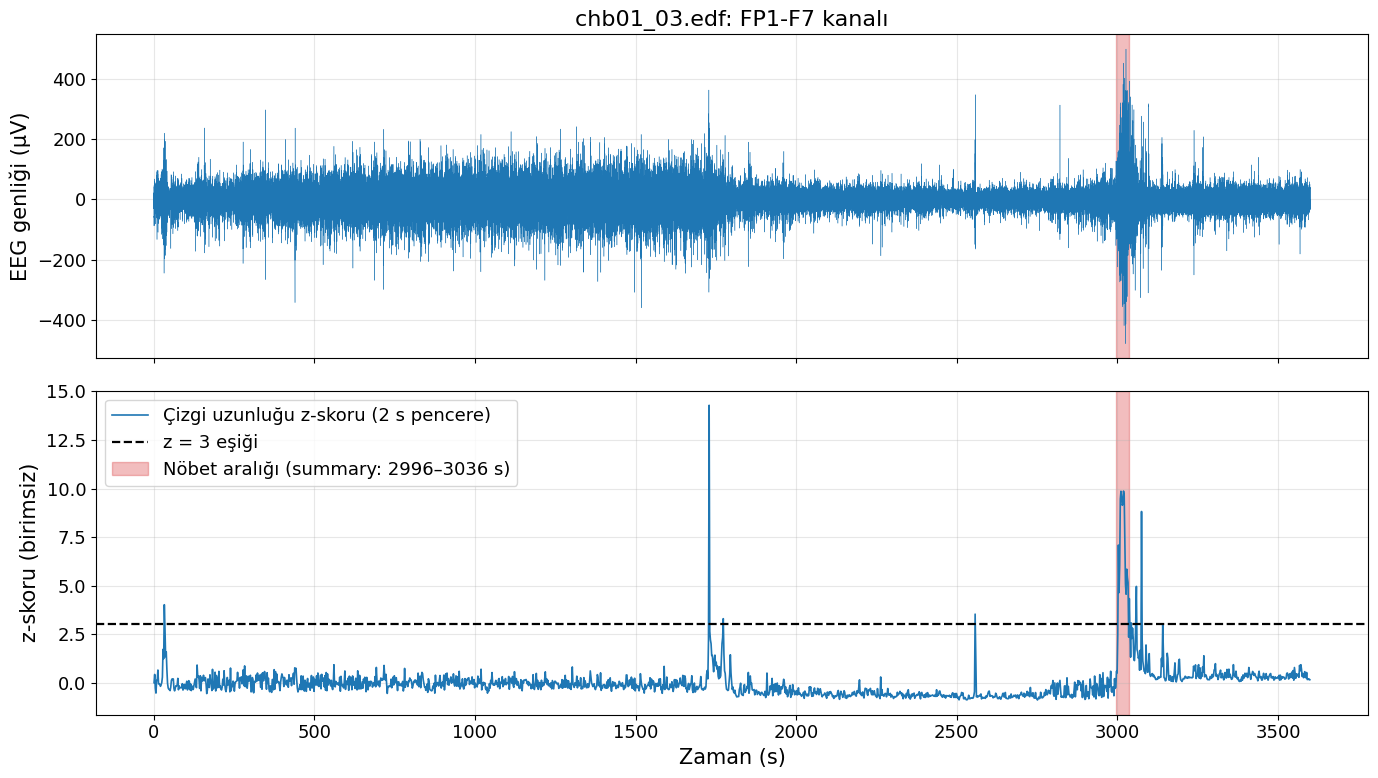

Kullanılan kanal: FP1-F7 | fs: 256 Hz | süre: 3600 s | pencere sayısı: 1800
Nöbet aralığı (summary'den okundu): [(2996, 3036)]
Nöbet aralığındaki pencere sayısı: 20 | bu pencerelerde en yüksek z: 9.87
Kayıtta z>3 olan pencere sayısı: toplam 26, nöbet içinde 16, nöbet dışında 10
ozellikler.csv ile z farkı (en büyük mutlak): 4.44e-16


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
import os, re, sys, subprocess, urllib.request, warnings
import numpy as np
import matplotlib.pyplot as plt

try:
    import mne
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mne"])
    import mne

warnings.filterwarnings("ignore", category=RuntimeWarning)

AWS = "https://physionet-open.s3.amazonaws.com/chbmit/1.0.0/"
YEDEK = "https://physionet.org/files/chbmit/1.0.0/"

def indir(yol):
    os.makedirs(os.path.dirname(yol), exist_ok=True)
    if os.path.exists(yol) and os.path.getsize(yol) > 0:
        return
    for taban in (AWS, YEDEK):
        try:
            urllib.request.urlretrieve(taban + yol, yol)
            print(f"İndirildi ({taban.split('/')[2]}): {yol}")
            return
        except Exception as hata:
            print(f"UYARI: {taban.split('/')[2]} üzerinden inmedi: {yol} ({hata})")
            if os.path.exists(yol):
                os.remove(yol)
    raise RuntimeError(f"Hiçbir adresten inmedi: {yol}")

HASTA, FNAME = "chb01", "chb01_03.edf"
indir(f"{HASTA}/{FNAME}")
indir(f"{HASTA}/{HASTA}-summary.txt")

# 1) Kaydı oku
raw = mne.io.read_raw_edf(f"{HASTA}/{FNAME}", preload=True, verbose=False)
fs = int(raw.info["sfreq"])
veri = raw.get_data()
zaman = raw.times
KANAL = 0
kanal_adi = raw.ch_names[KANAL]
eeg_uv = veri[KANAL] * 1e6  # V -> µV

# 2) Çizgi uzunluğu z-skoru (önceki hücrelerle aynı: 2 sn pencere, 23 kanal ortalaması, kayıt içi z, N-1)
ornek = 2 * fs
n_pencere = veri.shape[1] // ornek
kesit = veri[:, :n_pencere * ornek].reshape(veri.shape[0], n_pencere, ornek)
cizgi = np.abs(np.diff(kesit, axis=2)).sum(axis=2).mean(axis=0)
z = (cizgi - cizgi.mean()) / cizgi.std(ddof=1)
pencere_merkez = np.arange(n_pencere) * 2 + 1

# 3) Nöbet aralığı summary'den
with open(f"{HASTA}/{HASTA}-summary.txt", "r") as f:
    icerik = f.read()
blok = re.search(rf"File Name:\s*{re.escape(FNAME)}\s*\n(.*?)(?=File Name:|\Z)", icerik, re.DOTALL)
baslar = [int(x) for x in re.findall(r'Seizure(?:\s+\d+)?\s+Start Time:\s*(\d+)', blok.group(1))]
bitisler = [int(x) for x in re.findall(r'Seizure(?:\s+\d+)?\s+End Time:\s*(\d+)', blok.group(1))]
assert baslar and len(baslar) == len(bitisler), "Nöbet aralığı okunamadı"

# 4) Şekil
plt.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 16,
                     "legend.fontsize": 13, "xtick.labelsize": 13, "ytick.labelsize": 13})
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

ax1.plot(zaman, eeg_uv, color="tab:blue", linewidth=0.3)
ax1.set_ylabel("EEG genliği (µV)")
ax1.set_title(f"{FNAME}: {kanal_adi} kanalı")

ax2.plot(pencere_merkez, z, color="tab:blue", linewidth=1.2, label="Çizgi uzunluğu z-skoru (2 s pencere)")
ax2.axhline(3, color="black", linestyle="--", linewidth=1.6, label="z = 3 eşiği")
ax2.set_ylabel("z-skoru (birimsiz)")
ax2.set_xlabel("Zaman (s)")

for i, (s, e) in enumerate(zip(baslar, bitisler)):
    ax1.axvspan(s, e, color="tab:red", alpha=0.3)
    ax2.axvspan(s, e, color="tab:red", alpha=0.3,
                label=f"Nöbet aralığı (summary: {s}–{e} s)" if i == 0 else None)

ax2.legend(loc="upper left")
ax1.grid(alpha=0.3); ax2.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("sekil1_chb01_03.png", dpi=200, bbox_inches="tight")
plt.show()

# 5) Çıktıda kontrol edeceğin değerler
print(f"Kullanılan kanal: {kanal_adi} | fs: {fs} Hz | süre: {zaman[-1]:.0f} s | pencere sayısı: {n_pencere}")
print(f"Nöbet aralığı (summary'den okundu): {list(zip(baslar, bitisler))}")
ic = np.zeros(n_pencere, dtype=bool)
for s, e in zip(baslar, bitisler):
    ic |= (pencere_merkez - 1 + 2 > s) & (pencere_merkez - 1 < e)
print(f"Nöbet aralığındaki pencere sayısı: {int(ic.sum())} | bu pencerelerde en yüksek z: {z[ic].max():.2f}")
print(f"Kayıtta z>3 olan pencere sayısı: toplam {int((z > 3).sum())}, nöbet içinde {int((z[ic] > 3).sum())}, nöbet dışında {int((z[~ic] > 3).sum())}")

if os.path.exists("ozellikler.csv"):
    import pandas as pd
    eski = pd.read_csv("ozellikler.csv")
    eski = eski[eski["Hasta_Kayit"] == FNAME].sort_values("Pencere_No")
    print(f"ozellikler.csv ile z farkı (en büyük mutlak): {np.abs(eski['Z_Score'].to_numpy() - z).max():.2e}")

try:
    from google.colab import files
    files.download("sekil1_chb01_03.png")
except Exception:
    print("Dosya otomatik inmedi; sol taraftaki dosya panelinden sekil1_chb01_03.png'yi indir.")

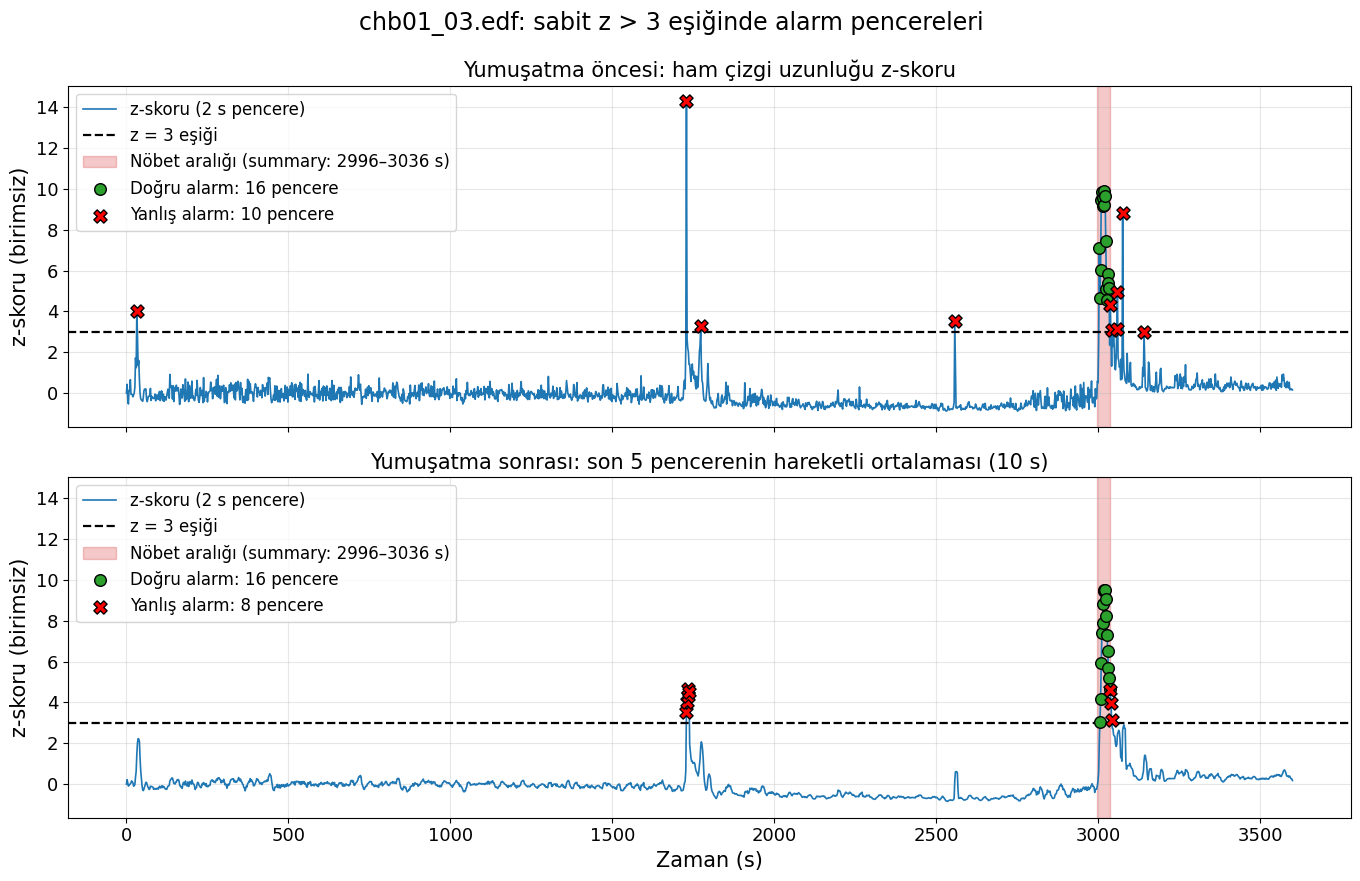

Yumuşatma yok : TP 16 | FP 10 | FN 4 | önceki tabloyla AYNI
   Yanlış alarm pencerelerinin başlangıç/merkez zamanları (s): [33, 1729, 1773, 2557, 3037, 3043, 3057, 3059, 3075, 3141]
Yumuşatma K=5 : TP 16 | FP 8 | FN 4 | önceki tabloyla AYNI
   Yanlış alarm pencerelerinin başlangıç/merkez zamanları (s): [1729, 1731, 1733, 1735, 1737, 3037, 3039, 3041]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
import os, re, sys, subprocess, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import mne
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mne"])
    import mne

warnings.filterwarnings("ignore", category=RuntimeWarning)

AWS = "https://physionet-open.s3.amazonaws.com/chbmit/1.0.0/"
YEDEK = "https://physionet.org/files/chbmit/1.0.0/"

def indir(yol):
    os.makedirs(os.path.dirname(yol), exist_ok=True)
    if os.path.exists(yol) and os.path.getsize(yol) > 0:
        return
    for taban in (AWS, YEDEK):
        try:
            urllib.request.urlretrieve(taban + yol, yol)
            print(f"İndirildi ({taban.split('/')[2]}): {yol}")
            return
        except Exception as hata:
            print(f"UYARI: {taban.split('/')[2]} üzerinden inmedi: {yol} ({hata})")
            if os.path.exists(yol):
                os.remove(yol)
    raise RuntimeError(f"Hiçbir adresten inmedi: {yol}")

HASTA, FNAME = "chb01", "chb01_03.edf"
K = 5        # yumuşatma penceresi (5 pencere = 10 s), önceki hücreyle aynı
ESIK = 3.0   # sabit z>3 baseline eşiği

indir(f"{HASTA}/{FNAME}")
indir(f"{HASTA}/{HASTA}-summary.txt")

# 1) Çizgi uzunluğu z-skoru (önceki hücrelerle aynı yöntem)
raw = mne.io.read_raw_edf(f"{HASTA}/{FNAME}", preload=True, verbose=False)
fs = int(raw.info["sfreq"])
veri = raw.get_data()
ornek = 2 * fs
n = veri.shape[1] // ornek
kesit = veri[:, :n * ornek].reshape(veri.shape[0], n, ornek)
cizgi = np.abs(np.diff(kesit, axis=2)).sum(axis=2).mean(axis=0)
z = (cizgi - cizgi.mean()) / cizgi.std(ddof=1)
z_yum = pd.Series(z).rolling(K, min_periods=1).mean().to_numpy()

# 2) Nöbet aralığı ve pencere etiketleri (summary'den)
with open(f"{HASTA}/{HASTA}-summary.txt", "r") as f:
    icerik = f.read()
blok = re.search(rf"File Name:\s*{re.escape(FNAME)}\s*\n(.*?)(?=File Name:|\Z)", icerik, re.DOTALL)
baslar = [int(x) for x in re.findall(r'Seizure(?:\s+\d+)?\s+Start Time:\s*(\d+)', blok.group(1))]
bitisler = [int(x) for x in re.findall(r'Seizure(?:\s+\d+)?\s+End Time:\s*(\d+)', blok.group(1))]
assert baslar and len(baslar) == len(bitisler), "Nöbet aralığı okunamadı"

bas = np.arange(n) * 2
bit = bas + 2
merkez = bas + 1
etiket = np.zeros(n, dtype=int)
for s, e in zip(baslar, bitisler):
    etiket[(bit > s) & (bas < e)] = 1

def siniflandir(zz):
    alarm = zz > ESIK
    tp = alarm & (etiket == 1)
    fp = alarm & (etiket == 0)
    fn = (~alarm) & (etiket == 1)
    return tp, fp, fn

# 3) Şekil
plt.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "legend.fontsize": 12, "xtick.labelsize": 13, "ytick.labelsize": 13})
fig, eksenler = plt.subplots(2, 1, figsize=(14, 9), sharex=True, sharey=True)

sonuclar = {}
for ax, zz, baslik, ad in [
    (eksenler[0], z, "Yumuşatma öncesi: ham çizgi uzunluğu z-skoru", "yok"),
    (eksenler[1], z_yum, f"Yumuşatma sonrası: son {K} pencerenin hareketli ortalaması ({K * 2} s)", f"K={K}"),
]:
    tp, fp, fn = siniflandir(zz)
    sonuclar[ad] = (int(tp.sum()), int(fp.sum()), int(fn.sum()), merkez[fp])
    ax.plot(merkez, zz, color="tab:blue", linewidth=1.2, label="z-skoru (2 s pencere)")
    ax.axhline(ESIK, color="black", linestyle="--", linewidth=1.6, label=f"z = {ESIK:g} eşiği")
    for i, (s, e) in enumerate(zip(baslar, bitisler)):
        ax.axvspan(s, e, color="tab:red", alpha=0.25,
                   label=f"Nöbet aralığı (summary: {s}–{e} s)" if i == 0 else None)
    ax.scatter(merkez[tp], zz[tp], s=70, marker="o", color="tab:green", edgecolor="black",
               zorder=5, label=f"Doğru alarm: {int(tp.sum())} pencere")
    ax.scatter(merkez[fp], zz[fp], s=90, marker="X", color="red", edgecolor="black",
               zorder=5, label=f"Yanlış alarm: {int(fp.sum())} pencere")
    ax.set_title(baslik)
    ax.set_ylabel("z-skoru (birimsiz)")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")

eksenler[1].set_xlabel("Zaman (s)")
fig.suptitle(f"{FNAME}: sabit z > {ESIK:g} eşiğinde alarm pencereleri", fontsize=17)
fig.tight_layout()
fig.savefig("sekil2_chb01_03_yumusatma.png", dpi=200, bbox_inches="tight")
plt.show()

# 4) Çıktıda kontrol edeceğin değerler
beklenen = {"yok": (16, 10, 4), "K=5": (16, 8, 4)}  # önceki tablodan: chb01, z>3 (TP, FP, FN)
for ad, (tp, fp, fn, fp_zamanlari) in sonuclar.items():
    print(f"Yumuşatma {ad:4s}: TP {tp} | FP {fp} | FN {fn} | önceki tabloyla "
          f"{'AYNI' if (tp, fp, fn) == beklenen[ad] else 'FARKLI'}")
    print(f"   Yanlış alarm pencerelerinin başlangıç/merkez zamanları (s): {fp_zamanlari.tolist()}")

try:
    from google.colab import files
    files.download("sekil2_chb01_03_yumusatma.png")
except Exception:
    print("Dosya otomatik inmedi; sol taraftaki dosya panelinden sekil2_chb01_03_yumusatma.png'yi indir.")

=== KONTROL (girilen F1'lerden hesaplanan ort ± std, N-1  vs  senin özetin) ===
yok  z3       hesap: 0.297 ± 0.299 | özet: 0.297 ± 0.299 | AYNI
yok  LOPO     hesap: 0.308 ± 0.189 | özet: 0.308 ± 0.189 | AYNI
yok  Iyimser  hesap: 0.443 ± 0.248 | özet: 0.443 ± 0.248 | AYNI
K=5  z3       hesap: 0.349 ± 0.332 | özet: 0.349 ± 0.332 | AYNI
K=5  LOPO     hesap: 0.256 ± 0.241 | özet: 0.257 ± 0.241 | FARKLI
K=5  Iyimser  hesap: 0.503 ± 0.243 | özet: 0.503 ± 0.243 | AYNI


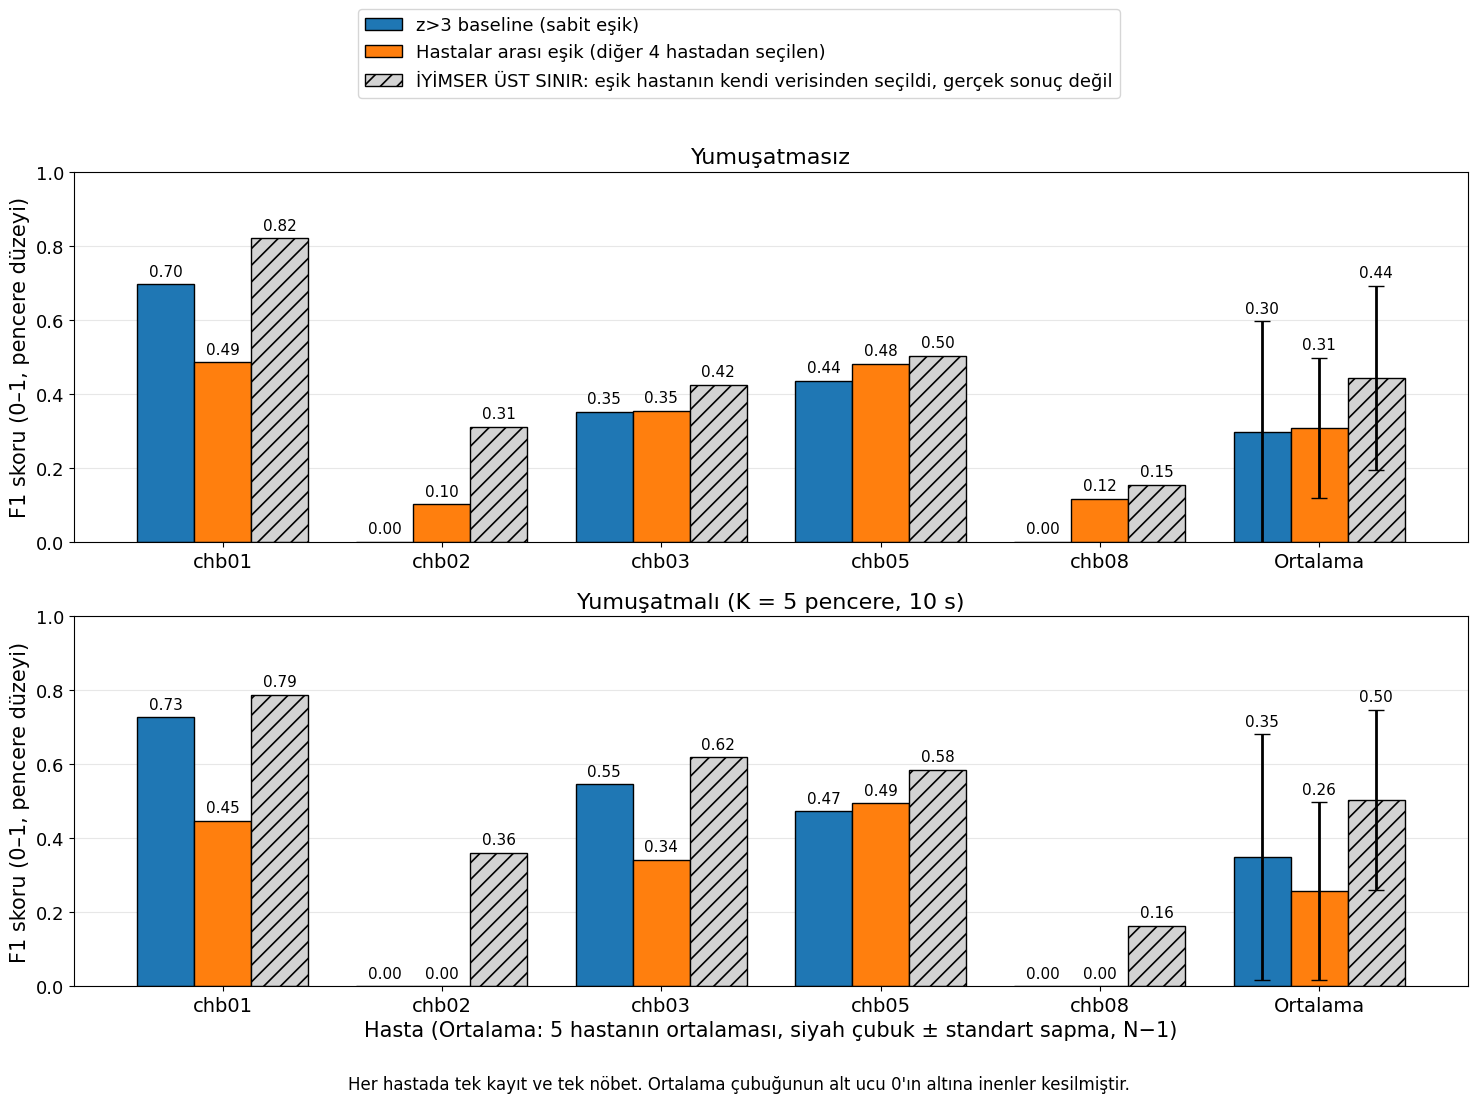

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import numpy as np
import matplotlib.pyplot as plt

hastalar = ["chb01", "chb02", "chb03", "chb05", "chb08"]

# Senin yapıştırdığın "HASTA BAŞINA" tablosundaki F1 değerleri (hasta sırası yukarıdaki gibi)
F1 = {
    "yok": {
        "z3":      [0.696, 0.000, 0.351, 0.436, 0.000],
        "LOPO":    [0.486, 0.102, 0.354, 0.481, 0.116],
        "Iyimser": [0.821, 0.312, 0.424, 0.503, 0.155],
    },
    "K=5": {
        "z3":      [0.727, 0.000, 0.545, 0.473, 0.000],
        "LOPO":    [0.447, 0.000, 0.341, 0.494, 0.000],
        "Iyimser": [0.788, 0.360, 0.618, 0.585, 0.164],
    },
}
# Senin yapıştırdığın "ORTALAMA ± STANDART SAPMA (N-1)" satırları
OZET = {
    "yok": {"z3": (0.297, 0.299), "LOPO": (0.308, 0.189), "Iyimser": (0.443, 0.248)},
    "K=5": {"z3": (0.349, 0.332), "LOPO": (0.257, 0.241), "Iyimser": (0.503, 0.243)},
}

# Kontrol: girilen değerlerden hesaplanan ortalama ± std, yapıştırdığın özetle aynı mı?
print("=== KONTROL (girilen F1'lerden hesaplanan ort ± std, N-1  vs  senin özetin) ===")
for yum in F1:
    for yontem in F1[yum]:
        v = np.array(F1[yum][yontem])
        ort, sd = round(v.mean(), 3), round(v.std(ddof=1), 3)
        beklenen = OZET[yum][yontem]
        durum = "AYNI" if (ort, sd) == beklenen else "FARKLI"
        print(f"{yum:4s} {yontem:8s} hesap: {ort:.3f} ± {sd:.3f} | özet: {beklenen[0]:.3f} ± {beklenen[1]:.3f} | {durum}")

# Şekil
plt.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 16,
                     "legend.fontsize": 13, "xtick.labelsize": 14, "ytick.labelsize": 13,
                     "hatch.linewidth": 1.2})

yontemler = [
    ("z3", "z>3 baseline (sabit eşik)", "tab:blue", None),
    ("LOPO", "Hastalar arası eşik (diğer 4 hastadan seçilen)", "tab:orange", None),
    ("Iyimser", "İYİMSER ÜST SINIR: eşik hastanın kendi verisinden seçildi, gerçek sonuç değil", "lightgray", "//"),
]
gruplar = hastalar + ["Ortalama"]
x = np.arange(len(gruplar))
w = 0.26

fig, eksenler = plt.subplots(2, 1, figsize=(15, 11), sharey=True)
for ax, (yum, baslik) in zip(eksenler, [("yok", "Yumuşatmasız"), ("K=5", "Yumuşatmalı (K = 5 pencere, 10 s)")]):
    for j, (anahtar, etiket, renk, hatch) in enumerate(yontemler):
        degerler = np.array(F1[yum][anahtar])
        ort, sd = degerler.mean(), degerler.std(ddof=1)
        yukseklik = np.append(degerler, ort)
        konum = x + (j - 1) * w
        ax.bar(konum, yukseklik, w, color=renk, edgecolor="black", hatch=hatch, label=etiket)
        ax.errorbar(konum[-1], ort, yerr=sd, color="black", capsize=6, linewidth=2)
        for i, (xi, yi) in enumerate(zip(konum, yukseklik)):
            ust = yi + (sd if i == len(konum) - 1 else 0)
            ax.text(xi, ust + 0.015, f"{yi:.2f}", ha="center", va="bottom", fontsize=11)
    ax.set_title(baslik)
    ax.set_ylabel("F1 skoru (0–1, pencere düzeyi)")
    ax.set_xticks(x)
    ax.set_xticklabels(gruplar)
    ax.set_ylim(0, 1.0)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

eksenler[1].set_xlabel("Hasta (Ortalama: 5 hastanın ortalaması, siyah çubuk ± standart sapma, N−1)")

handles, etiketler = eksenler[0].get_legend_handles_labels()
fig.legend(handles, etiketler, loc="upper center", ncol=1, frameon=True, bbox_to_anchor=(0.5, 0.995))
fig.text(0.5, 0.005, "Her hastada tek kayıt ve tek nöbet. Ortalama çubuğunun alt ucu 0'ın altına inenler kesilmiştir.",
         ha="center", fontsize=12)
fig.tight_layout(rect=[0, 0.03, 1, 0.88])
fig.savefig("sekil3_hasta_F1.png", dpi=200, bbox_inches="tight")
plt.show()

try:
    from google.colab import files
    files.download("sekil3_hasta_F1.png")
except Exception:
    print("Dosya otomatik inmedi; sol taraftaki dosya panelinden sekil3_hasta_F1.png'yi indir.")